# Instance segmentation

This example shows how to augment an image together with many instance masks, e.g. for training Mask R-CNN-like
models. Every mask is a separate item of a `DataContainer`, so all of them get exactly the same transformation as
the image.

The data come with [scikit-image](https://scikit-image.org): an immunohistochemistry image of a colon tissue.
The masks of the cell nuclei are obtained with a simple segmentation pipeline below. They are not perfect,
but good enough to demonstrate the augmentations.

In [1]:
%matplotlib inline
# JPEG keeps the notebook small, since the figures are photos
%config InlineBackend.figure_formats = ['jpeg']
import random

import cv2
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import patches

import solt
import solt.transforms as slt

# SOLT samples the transforms with the `random` module
random.seed(42)
np.random.seed(42)

from scipy import ndimage as ndi
from skimage import color, data, feature, filters, measure, morphology, segmentation

## Getting the data

In [2]:
def segment_nuclei(img):
    """Returns a list of binary masks (uint8, 0 or 255), one per nucleus."""
    hed = color.rgb2hed(img)
    # Nuclei are stained by hematoxylin (blue), the rest of the cells by DAB (brown)
    hema = filters.gaussian(hed[..., 0], sigma=1)
    dab = filters.gaussian(hed[..., 2], sigma=1)
    foreground = (hema > 1.15 * filters.threshold_otsu(hema)) & (dab < filters.threshold_otsu(dab))
    foreground = morphology.remove_small_objects(foreground, max_size=60)
    foreground = morphology.remove_small_holes(foreground, max_size=60)
    foreground = morphology.opening(foreground, morphology.disk(2))

    # Splitting the touching nuclei with the watershed
    distance = ndi.distance_transform_edt(foreground)
    peaks = feature.peak_local_max(filters.gaussian(distance, 1), min_distance=6, labels=measure.label(foreground))
    markers = np.zeros(foreground.shape, dtype=int)
    markers[tuple(peaks.T)] = np.arange(1, len(peaks) + 1)
    instances = segmentation.watershed(-distance, markers, mask=foreground)

    return [(instances == i).astype(np.uint8) * 255 for i in range(1, instances.max() + 1)]


img = data.immunohistochemistry()
masks = segment_nuclei(img)
print(f"Image: {img.shape}, {len(masks)} nuclei")

Image: (512, 512, 3), 213 nuclei


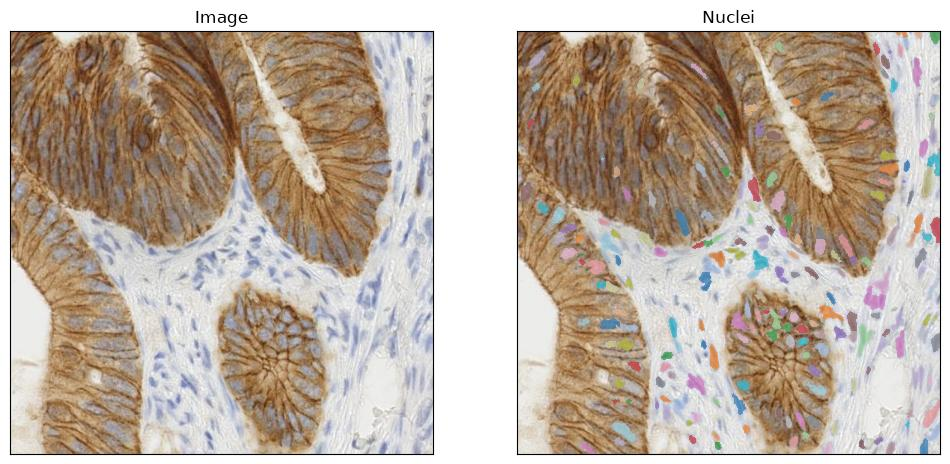

In [3]:
def show_instances(ax, img, masks):
    instances = np.zeros(img.shape[:2], dtype=int)
    for i, mask in enumerate(masks):
        instances[mask == 255] = i + 1
    ax.imshow(img)
    ax.imshow(np.ma.masked_array(instances % 20, instances == 0), cmap='tab20', alpha=0.6, interpolation='nearest')
    ax.set_xticks([])
    ax.set_yticks([])


fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(img)
ax[0].set_xticks([])
ax[0].set_yticks([])
ax[0].set_title('Image')
show_instances(ax[1], img, masks)
ax[1].set_title('Nuclei')
plt.show()

## Defining a pipeline

The masks use the nearest neighbour interpolation by default, so they stay binary, while the image is
interpolated bicubically here.

In [4]:
stream = solt.Stream([
    slt.Rotate(angle_range=(-90, 90), p=1, interpolation='bicubic'),
    slt.Pad(512),
    slt.Crop(512, crop_mode='c'),
    slt.Crop(384, crop_mode='r'),
])
print(stream.to_yaml())

stream:
  ignore_fast_mode: false
  in_place: true
  interpolation: null
  max_bbox_area_loss: 0.9
  max_bbox_outside: 0.5
  optimize_stack: false
  padding: null
  shuffle: false
  transforms:
  - rotate:
      angle_range:
      - -90
      - 90
      ignore_fast_mode: false
      ignore_state: true
      interpolation:
      - bicubic
      - inherit
      p: 1
      padding:
      - z
      - inherit
  - pad:
      pad_to:
      - 512
      - 512
      padding:
      - z
      - inherit
  - crop:
      crop_mode: c
      crop_to:
      - 512
      - 512
  - crop:
      crop_mode: r
      crop_to:
      - 384
      - 384



## Augmentation results

Here, we use the dict API: the image goes under the key `image`, and the list of masks under `masks`.

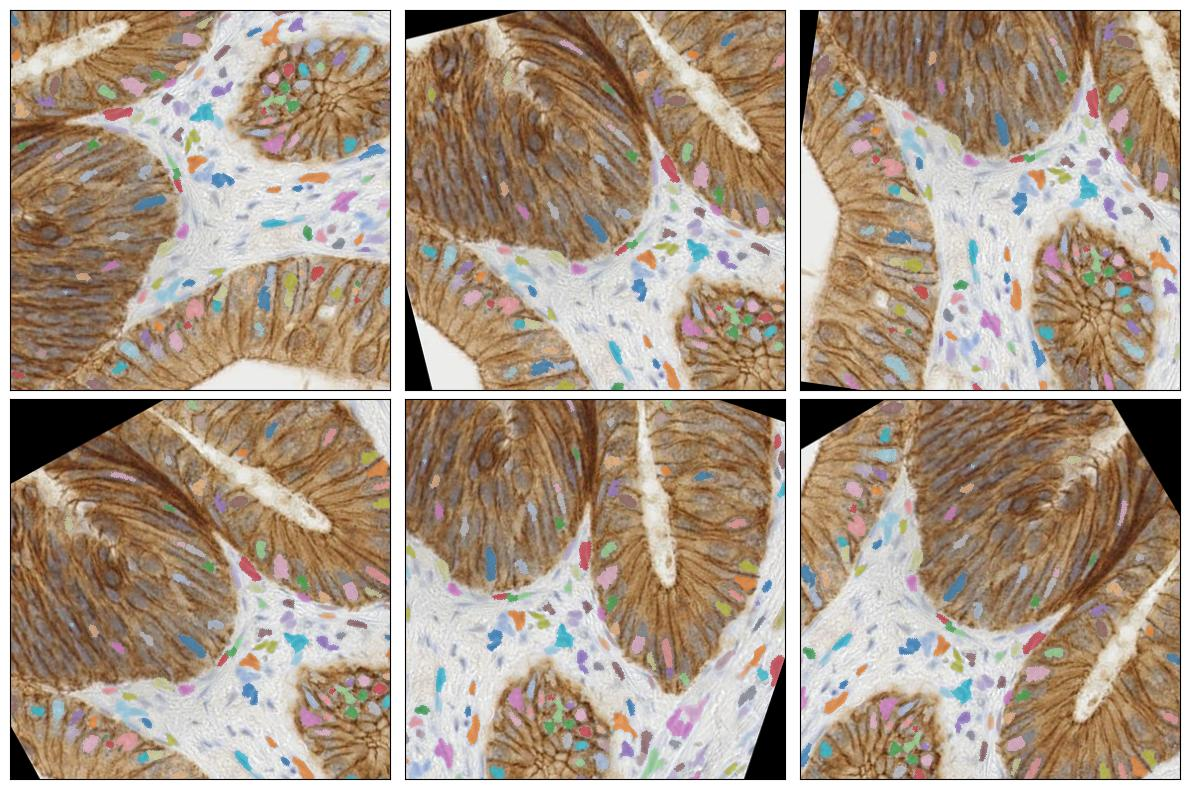

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax in axes.ravel():
    res = stream({'image': img, 'masks': masks}, return_torch=False)
    img_res, masks_res = res.data[0], res.data[1:]
    show_instances(ax, img_res, masks_res)
plt.tight_layout()
plt.show()